# 07b — Supplementary Double-Held-Out Robustness Stress Test

## E5: Held-out L3 language + held-out Gaussian sensor noise

This notebook is a **supplementary exploratory analysis** performed only **after** Notebook 07 completed its predeclared definitive evaluation.

It does **not** train, tune, select, replace, or modify any model. The six primary frozen checkpoints are reused exactly as they were evaluated in Notebook 07:

- **M1** — seeds 42, 123, 2026
- **M2-LE** — seeds 42, 123, 2026

### Scientific purpose

Notebook 07 established separate evidence for:

- held-out linguistic robustness (`E1_L3`), and
- transfer to held-out Gaussian sensor noise (`E3_HELDOUT_NOISE`).

The original combined condition (`E4_COMBINED`) mixed **held-out L3 language** with a **seen-family photometric shift**. E5 therefore asks a stricter follow-up question:

> **Does the M2-LE robustness advantage persist when both the language perturbation and the visual perturbation belong to categories absent from robustness training?**

### Methodological status

E5 is **exploratory/supplementary**, not retroactively confirmatory. Its result must not be used to change the frozen training budget, checkpoints, hyperparameters, or model-selection decisions.


## 1. Frozen exploratory protocol

- Condition: `E5_DOUBLE_HELDOUT`
- Language: held-out `L3`
- Visual corruption: held-out Gaussian noise, `σ = 0.05`
- Tasks: all 10 LIBERO-Spatial tasks
- Replicas: 5 per task
- Models: M1 and M2-LE
- Training seeds: 42, 123, 2026
- Episodes: `2 × 3 × 10 × 5 = 300`
- Episode reset seeds are paired exactly across M1 and M2-LE.
- Statistical interpretation is exploratory. A **raw exact McNemar p-value** is reported for the single supplementary hypothesis; it is not inserted into Notebook 07's original Holm family.


## 2. Environment, frozen-model handoff, and Notebook 07 prerequisite


In [2]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from datetime import datetime
import gc
import hashlib
import json
import math
import subprocess
import sys
import time
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LIBERO_SUITE = "libero_spatial"
EPISODES_PER_TASK = 5
BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_SEED = 20260827
PRIMARY_VARIANTS = ["M1", "M2-LE"]
PRIMARY_SEEDS = [42, 123, 2026]
E5_CONDITION_ID = "E5_DOUBLE_HELDOUT"


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    if current.name == "notebooks":
        return current.parent
    return current


REPO_ROOT = find_repo_root(Path.cwd())
RESULTS_DIR = REPO_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics" / "supplementary_double_heldout"
FIGURES_DIR = RESULTS_DIR / "figures" / "supplementary_double_heldout"
QUALITATIVE_DIR = RESULTS_DIR / "qualitative" / "supplementary_double_heldout"
EXPERIMENT_CONFIG_DIR = REPO_ROOT / "configs" / "experiments"

for directory in [METRICS_DIR, FIGURES_DIR, QUALITATIVE_DIR, EXPERIMENT_CONFIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=repo_root, text=True
        ).strip()
    except Exception:
        return None


PROJECT_GIT_SHA = git_sha(REPO_ROOT)

NOTEBOOK06_SUMMARY_PATH = (
    REPO_ROOT / "results" / "metrics" / "validated_final_retraining" / "notebook06_summary.json"
)
NOTEBOOK07_HANDOFF_PATH = EXPERIMENT_CONFIG_DIR / "notebook07_definitive_evaluation_handoff_v1.json"
NOTEBOOK07_SUMMARY_PATH = (
    REPO_ROOT / "results" / "metrics" / "definitive_robustness_evaluation" / "notebook07_summary.json"
)
NOTEBOOK07_HEADLINE_PATH = (
    REPO_ROOT / "results" / "metrics" / "definitive_robustness_evaluation" / "definitive_headline_results.csv"
)
NOTEBOOK07_PER_SEED_PATH = (
    REPO_ROOT / "results" / "metrics" / "definitive_robustness_evaluation" / "primary_per_seed_success.csv"
)

for path in [NOTEBOOK06_SUMMARY_PATH, NOTEBOOK07_HANDOFF_PATH, NOTEBOOK07_SUMMARY_PATH,
             NOTEBOOK07_HEADLINE_PATH, NOTEBOOK07_PER_SEED_PATH]:
    assert path.exists(), f"Missing prerequisite artifact: {path}"

with open(NOTEBOOK06_SUMMARY_PATH, "r") as f:
    notebook06_summary = json.load(f)
with open(NOTEBOOK07_HANDOFF_PATH, "r") as f:
    evaluation_handoff = json.load(f)
with open(NOTEBOOK07_SUMMARY_PATH, "r") as f:
    notebook07_summary = json.load(f)

assert notebook06_summary["technical_status"] == "PASS"
assert notebook07_summary["technical_status"] == "PASS"
assert int(notebook07_summary["planned_episodes"]) == 2050
assert int(notebook07_summary["completed_episodes"]) == 2050
assert notebook07_summary["post_ood_model_replacement"] is False
assert evaluation_handoff["training_budget_frozen"] is True
assert evaluation_handoff["model_selection_after_ood_forbidden"] is True
assert int(evaluation_handoff["final_training_steps"]) == 25000
assert evaluation_handoff["primary_variants"] == PRIMARY_VARIANTS
assert evaluation_handoff["primary_seeds"] == PRIMARY_SEEDS
assert torch.cuda.is_available(), "07b requires the same validated CUDA environment as Notebook 07."

display(pd.DataFrame([{
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "project_git_sha": PROJECT_GIT_SHA,
    "Notebook 06": notebook06_summary["technical_status"],
    "Notebook 07": notebook07_summary["technical_status"],
    "Notebook 07 episodes": f"{notebook07_summary['completed_episodes']}/{notebook07_summary['planned_episodes']}",
    "frozen_training_steps": evaluation_handoff["final_training_steps"],
    "07b_status": "SUPPLEMENTARY_EXPLORATORY",
}]).T.rename(columns={0: "Value"}))

print("NOTEBOOK 07 PREREQUISITE + FROZEN HANDOFF: PASS")


,Value
python,3.12.14
torch,2.11.0+cu128
gpu,NVIDIA GeForce RTX 5090
project_git_sha,25bc0f04bcc16112d1d67dd97a3bd10117514b9c
Notebook 06,PASS
Notebook 07,PASS
Notebook 07 episodes,2050/2050
frozen_training_steps,25000
07b_status,SUPPLEMENTARY_EXPLORATORY


NOTEBOOK 07 PREREQUISITE + FROZEN HANDOFF: PASS


## 3. Load and restrict the frozen model registry


In [3]:
FINAL_MODEL_REGISTRY_PATH = REPO_ROOT / evaluation_handoff["final_model_registry"]
assert FINAL_MODEL_REGISTRY_PATH.exists()

full_registry_df = pd.read_csv(FINAL_MODEL_REGISTRY_PATH)
required_registry_columns = {
    "variant", "seed", "role", "training_steps", "checkpoint",
    "checkpoint_signature", "validation_loss",
}
assert required_registry_columns.issubset(full_registry_df.columns)
assert len(full_registry_df) == 8

model_registry_df = full_registry_df[
    full_registry_df["variant"].isin(PRIMARY_VARIANTS)
    & full_registry_df["seed"].astype(int).isin(PRIMARY_SEEDS)
].copy()

model_registry_df["seed"] = model_registry_df["seed"].astype(int)
model_registry_df["run_id"] = [
    f"{variant.replace('-', '')}_seed{seed}"
    for variant, seed in zip(model_registry_df["variant"], model_registry_df["seed"])
]

expected_pairs = {
    ("M1", 42), ("M1", 123), ("M1", 2026),
    ("M2-LE", 42), ("M2-LE", 123), ("M2-LE", 2026),
}
assert set(zip(model_registry_df["variant"], model_registry_df["seed"])) == expected_pairs
assert len(model_registry_df) == 6
assert (model_registry_df["training_steps"].astype(int) == 25000).all()

for row in model_registry_df.itertuples():
    checkpoint = REPO_ROOT / str(row.checkpoint)
    assert checkpoint.exists(), f"Checkpoint missing: {checkpoint}"
    assert (checkpoint / "config.json").exists(), f"Config missing: {checkpoint}"

display(model_registry_df[[
    "run_id", "variant", "seed", "training_steps", "validation_loss", "checkpoint"
]].sort_values(["variant", "seed"]))

print("SIX PRIMARY FROZEN CHECKPOINTS: PASS")


,run_id,variant,seed,training_steps,validation_loss,checkpoint
0,M1_seed42,M1,42,25000,0.570412,experiments/final_budget_validation/m1_standar...
1,M1_seed123,M1,123,25000,0.564678,experiments/final_budget_validation/m1_standar...
2,M1_seed2026,M1,2026,25000,0.557629,experiments/final_budget_validation/m1_standar...
5,M2LE_seed42,M2-LE,42,25000,0.581579,experiments/validated_final_retraining/m2le_se...
6,M2LE_seed123,M2-LE,123,25000,0.557852,experiments/validated_final_retraining/m2le_se...
7,M2LE_seed2026,M2-LE,2026,25000,0.578886,experiments/validated_final_retraining/m2le_se...


SIX PRIMARY FROZEN CHECKPOINTS: PASS


## 4. Load task mapping and frozen L3 language set


In [4]:
TASK_MAPPING_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "dataset_eda"
    / "libero_spatial_dataset_task_mapping.csv"
)

LANGUAGE_TABLE_PATH = (
    REPO_ROOT
    / "configs"
    / "experiments"
    / "libero_spatial_language_augmentations_v1.csv"
)

assert TASK_MAPPING_PATH.exists()
assert LANGUAGE_TABLE_PATH.exists()

task_mapping_df = pd.read_csv(
    TASK_MAPPING_PATH
)

language_df = pd.read_csv(
    LANGUAGE_TABLE_PATH
)

required_mapping_columns = {
    "suite_task_id",
    "dataset_task_index",
    "benchmark_instruction",
}

assert required_mapping_columns.issubset(
    task_mapping_df.columns
)

assert len(
    task_mapping_df
) == 10

assert task_mapping_df[
    "suite_task_id"
].nunique() == 10

assert task_mapping_df[
    "dataset_task_index"
].nunique() == 10

assert len(
    language_df
) == 40

assert set(
    language_df[
        "level"
    ]
) == {
    "L0",
    "L1",
    "L2",
    "L3",
}


suite_to_dataset_task = {
    int(
        row[
            "suite_task_id"
        ]
    ): int(
        row[
            "dataset_task_index"
        ]
    )
    for _, row
    in task_mapping_df.iterrows()
}


language_lookup = {
    (
        int(
            row[
                "task_id"
            ]
        ),
        str(
            row[
                "level"
            ]
        ),
    ): str(
        row[
            "augmented_instruction"
        ]
    )
    for _, row
    in language_df.iterrows()
}


for suite_task_id, dataset_task_id in (
    suite_to_dataset_task.items()
):
    for level in [
        "L0",
        "L1",
        "L2",
        "L3",
    ]:
        assert (
            dataset_task_id,
            level,
        ) in language_lookup


display(
    task_mapping_df[
        [
            "suite_task_id",
            "dataset_task_index",
            "benchmark_instruction",
        ]
    ]
)

print("TASK + HELD-OUT LANGUAGE MAPPING: PASS")


,suite_task_id,dataset_task_index,benchmark_instruction
0,0,34,pick up the black bowl between the plate and t...
1,1,37,pick up the black bowl next to the ramekin and...
2,2,38,pick up the black bowl from table center and p...
3,3,35,pick up the black bowl on the cookie box and p...
4,4,31,pick up the black bowl in the top drawer of th...
5,5,32,pick up the black bowl on the ramekin and plac...
6,6,30,pick up the black bowl next to the cookie box ...
7,7,33,pick up the black bowl on the stove and place ...
8,8,36,pick up the black bowl next to the plate and p...
9,9,39,pick up the black bowl on the wooden cabinet a...


TASK + HELD-OUT LANGUAGE MAPPING: PASS


## 5. Define E5 and the 300-episode exploratory plan

The only new experimental condition is a **composition of two already-defined held-out components**. No new corruption magnitude is tuned here: Gaussian noise remains exactly `σ=0.05`, as in Notebook 07.


In [5]:
CONDITIONS = {
    E5_CONDITION_ID: {
        "label": "L3 + held-out Gaussian noise",
        "language_level": "L3",
        "image_shift": "HELDOUT_NOISE",
        "shift_role": "double_heldout_exploratory",
    }
}

run_lookup = {
    (str(row.variant), int(row.seed)): str(row.run_id)
    for row in model_registry_df.itertuples()
}

plan_rows = []
for variant in PRIMARY_VARIANTS:
    for seed in PRIMARY_SEEDS:
        plan_rows.append({
            "phase": "C_supplementary_double_heldout",
            "run_id": run_lookup[(variant, seed)],
            "variant": variant,
            "model_seed": seed,
            "condition_id": E5_CONDITION_ID,
            "task_count": 10,
            "episodes_per_task": EPISODES_PER_TASK,
            "episodes": 10 * EPISODES_PER_TASK,
        })

evaluation_plan_df = pd.DataFrame(plan_rows).sort_values(
    ["variant", "model_seed"]
).reset_index(drop=True)
PLANNED_EPISODES = int(evaluation_plan_df["episodes"].sum())

assert len(evaluation_plan_df) == 6
assert PLANNED_EPISODES == 300
assert set(evaluation_plan_df["variant"]) == set(PRIMARY_VARIANTS)
assert set(evaluation_plan_df["model_seed"]) == set(PRIMARY_SEEDS)

display(pd.DataFrame([
    {"condition_id": E5_CONDITION_ID, **CONDITIONS[E5_CONDITION_ID]}
]))
display(evaluation_plan_df)
print(f"SUPPLEMENTARY E5 PLAN: FROZEN | {PLANNED_EPISODES} episodes")


,condition_id,label,language_level,image_shift,shift_role
0,E5_DOUBLE_HELDOUT,L3 + held-out Gaussian noise,L3,HELDOUT_NOISE,double_heldout_exploratory


,phase,run_id,variant,model_seed,condition_id,task_count,episodes_per_task,episodes
0,C_supplementary_double_heldout,M1_seed42,M1,42,E5_DOUBLE_HELDOUT,10,5,50
1,C_supplementary_double_heldout,M1_seed123,M1,123,E5_DOUBLE_HELDOUT,10,5,50
2,C_supplementary_double_heldout,M1_seed2026,M1,2026,E5_DOUBLE_HELDOUT,10,5,50
3,C_supplementary_double_heldout,M2LE_seed42,M2-LE,42,E5_DOUBLE_HELDOUT,10,5,50
4,C_supplementary_double_heldout,M2LE_seed123,M2-LE,123,E5_DOUBLE_HELDOUT,10,5,50
5,C_supplementary_double_heldout,M2LE_seed2026,M2-LE,2026,E5_DOUBLE_HELDOUT,10,5,50


SUPPLEMENTARY E5 PLAN: FROZEN | 300 episodes


## 6. Freeze the supplementary protocol and independent cache identity


In [6]:
def canonical_json_hash(payload):
    encoded = json.dumps(
        payload, sort_keys=True, separators=(",", ":"), default=str
    ).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()

registry_protocol_rows = (
    model_registry_df[[
        "run_id", "variant", "seed", "training_steps", "checkpoint_signature"
    ]]
    .sort_values("run_id")
    .to_dict(orient="records")
)

evaluation_protocol = {
    "protocol_id": "supplementary_e5_double_heldout_v1",
    "source_notebook": "07b_supplementary_double_heldout_stress_test",
    "methodological_status": "posthoc_supplementary_exploratory",
    "source_notebook07_summary": str(NOTEBOOK07_SUMMARY_PATH.relative_to(REPO_ROOT)),
    "source_notebook07_handoff": str(NOTEBOOK07_HANDOFF_PATH.relative_to(REPO_ROOT)),
    "episodes_per_task": EPISODES_PER_TASK,
    "task_count": 10,
    "planned_episodes": PLANNED_EPISODES,
    "bootstrap_samples": BOOTSTRAP_SAMPLES,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "primary_variants": PRIMARY_VARIANTS,
    "primary_seeds": PRIMARY_SEEDS,
    "condition": CONDITIONS[E5_CONDITION_ID],
    "condition_id": E5_CONDITION_ID,
    "heldout_sensor_noise_sigma": 0.05,
    "model_registry": registry_protocol_rows,
    "evaluation_plan": evaluation_plan_df[[
        "phase", "run_id", "variant", "model_seed", "condition_id"
    ]].to_dict(orient="records"),
    "episode_seed_formula": "100000 + suite_task_id*100 + replica",
    "checkpoint_selection_after_results": False,
    "training_or_tuning_in_notebook07b": False,
    "included_in_original_notebook07_holm_family": False,
}

EVALUATION_PROTOCOL_SHA256 = canonical_json_hash(evaluation_protocol)
evaluation_protocol["protocol_sha256"] = EVALUATION_PROTOCOL_SHA256

EVALUATION_PROTOCOL_PATH = EXPERIMENT_CONFIG_DIR / "supplementary_e5_double_heldout_protocol_v1.json"
EVALUATION_PLAN_PATH = EXPERIMENT_CONFIG_DIR / "supplementary_e5_double_heldout_plan_v1.csv"

with open(EVALUATION_PROTOCOL_PATH, "w") as f:
    json.dump(evaluation_protocol, f, indent=2)
evaluation_plan_df.to_csv(EVALUATION_PLAN_PATH, index=False)

print("Protocol SHA256:", EVALUATION_PROTOCOL_SHA256)
print("Protocol:", EVALUATION_PROTOCOL_PATH)
print("SUPPLEMENTARY E5 PROTOCOL + CACHE IDENTITY: FROZEN")


Protocol SHA256: 39ecc39f6064a2345c153f46106765848c964d1d3db15e52d90cab795196f2d7
Protocol: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/supplementary_e5_double_heldout_protocol_v1.json
SUPPLEMENTARY E5 PROTOCOL + CACHE IDENTITY: FROZEN


## 7. Official LeRobot / LIBERO evaluation components


In [7]:
from lerobot.envs.configs import (
    LiberoEnv as LiberoEnvConfig,
)

try:
    from lerobot.envs.factory import (
        make_env,
        make_env_pre_post_processors,
    )
except ImportError:
    from lerobot.envs import (
        make_env,
        make_env_pre_post_processors,
    )

from lerobot.envs.utils import (
    preprocess_observation,
)

from lerobot.policies.factory import (
    make_pre_post_processors,
)

from lerobot.policies.smolvla.modeling_smolvla import (
    SmolVLAPolicy,
)

from lerobot.utils.constants import (
    ACTION,
)

print("LEROBOT SUPPLEMENTARY EVALUATION COMPONENTS: READY")


/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LEROBOT SUPPLEMENTARY EVALUATION COMPONENTS: READY


## 8. Deterministic visual perturbation functions


In [8]:
def apply_seen_photometric_shift(
    image: torch.Tensor,
):
    # Boundary combination from the M2-E training family:
    # brightness 0.85, contrast 1.15, saturation 0.85.
    x = image.to(
        torch.float32
    )

    x = x * 0.85

    mean = x.mean(
        dim=(
            -2,
            -1,
        ),
        keepdim=True,
    )

    x = (
        (
            x
            - mean
        )
        * 1.15
        + mean
    )

    if x.shape[
        -3
    ] >= 3:
        rgb = x[
            ...,
            :3,
            :,
            :,
        ]

        gray = (
            0.2989
            * rgb[
                ...,
                0:1,
                :,
                :,
            ]
            + 0.5870
            * rgb[
                ...,
                1:2,
                :,
                :,
            ]
            + 0.1140
            * rgb[
                ...,
                2:3,
                :,
                :,
            ]
        )

        rgb = (
            gray
            + (
                rgb
                - gray
            )
            * 0.85
        )

        x = x.clone()

        x[
            ...,
            :3,
            :,
            :,
        ] = rgb

    return x.clamp(
        0.0,
        1.0,
    )


def apply_heldout_sensor_noise(
    image: torch.Tensor,
    seed: int,
):
    x = image.to(
        torch.float32
    )

    generator = (
        torch.Generator(
            device=x.device
        )
    )

    generator.manual_seed(
        int(
            seed
        )
    )

    noise = torch.randn(
        x.shape,
        generator=generator,
        device=x.device,
        dtype=x.dtype,
    ) * 0.05

    return (
        x
        + noise
    ).clamp(
        0.0,
        1.0,
    )


def perturb_observation_images(
    observation: dict,
    image_shift: str,
    episode_seed: int,
    step_index: int,
):
    output = dict(
        observation
    )

    camera_keys = sorted(
        [
            key
            for key in output
            if key.startswith(
                "observation.images."
            )
        ]
    )

    for camera_index, camera_key in enumerate(
        camera_keys
    ):
        image = output[
            camera_key
        ]

        if not isinstance(
            image,
            torch.Tensor,
        ):
            continue

        if image_shift == "NONE":
            shifted = image

        elif image_shift == "SEEN_PHOTO":
            shifted = (
                apply_seen_photometric_shift(
                    image
                )
            )

        elif image_shift == "HELDOUT_NOISE":
            deterministic_noise_seed = (
                int(
                    episode_seed
                )
                * 10000
                + int(
                    step_index
                )
                * 100
                + camera_index
            )

            shifted = (
                apply_heldout_sensor_noise(
                    image,
                    seed=(
                        deterministic_noise_seed
                    ),
                )
            )

        else:
            raise ValueError(
                f"Unknown image_shift: {image_shift}"
            )

        output[
            camera_key
        ] = shifted

    return output


test_tensor = torch.full(
    (
        1,
        3,
        32,
        32,
    ),
    0.5,
)

assert torch.isfinite(
    apply_seen_photometric_shift(
        test_tensor
    )
).all()

assert torch.isfinite(
    apply_heldout_sensor_noise(
        test_tensor,
        seed=42,
    )
).all()

print("DETERMINISTIC E5 OBSERVATION PERTURBATIONS: PASS")


DETERMINISTIC E5 OBSERVATION PERTURBATIONS: PASS


## 9. Closed-loop cache and shared evaluator utilities


In [9]:
EPISODE_RESULTS_PATH = (
    METRICS_DIR
    / "closed_loop_episode_results.csv"
)

ERROR_LOG_PATH = (
    METRICS_DIR
    / "closed_loop_errors.jsonl"
)


def model_registry_row(
    run_id: str,
):
    matches = (
        model_registry_df[
            model_registry_df[
                "run_id"
            ]
            == run_id
        ]
    )

    assert len(
        matches
    ) == 1

    return matches.iloc[
        0
    ]


def episode_key(
    *,
    protocol_sha256,
    checkpoint_signature,
    run_id,
    condition_id,
    suite_task_id,
    replica,
):
    return (
        str(
            protocol_sha256
        ),
        str(
            checkpoint_signature
        ),
        str(
            run_id
        ),
        str(
            condition_id
        ),
        int(
            suite_task_id
        ),
        int(
            replica
        ),
    )


def read_episode_cache():
    if not EPISODE_RESULTS_PATH.exists():
        return pd.DataFrame()

    return pd.read_csv(
        EPISODE_RESULTS_PATH
    )


def active_episode_cache():
    cache = read_episode_cache()

    if cache.empty:
        return cache

    required = {
        "evaluation_protocol_sha256",
        "checkpoint_signature",
        "run_id",
        "condition_id",
        "suite_task_id",
        "replica",
        "system_status",
    }

    if not required.issubset(
        cache.columns
    ):
        return pd.DataFrame()

    active_signatures = set(
        model_registry_df[
            "checkpoint_signature"
        ].astype(str)
    )

    return cache[
        (
            cache[
                "evaluation_protocol_sha256"
            ]
            == EVALUATION_PROTOCOL_SHA256
        )
        & (
            cache[
                "checkpoint_signature"
            ]
            .astype(str)
            .isin(
                active_signatures
            )
        )
    ].copy()


def completed_episode_keys():
    cache = active_episode_cache()

    if cache.empty:
        return set()

    passed = cache[
        cache[
            "system_status"
        ]
        == "PASS"
    ]

    return {
        episode_key(
            protocol_sha256=(
                row.evaluation_protocol_sha256
            ),
            checkpoint_signature=(
                row.checkpoint_signature
            ),
            run_id=(
                row.run_id
            ),
            condition_id=(
                row.condition_id
            ),
            suite_task_id=(
                row.suite_task_id
            ),
            replica=(
                row.replica
            ),
        )
        for row in passed.itertuples()
    }


def append_episode_result(
    row,
):
    row_df = pd.DataFrame(
        [
            row
        ]
    )

    write_header = (
        not EPISODE_RESULTS_PATH.exists()
    )

    row_df.to_csv(
        EPISODE_RESULTS_PATH,
        mode="a",
        header=write_header,
        index=False,
    )


def append_error_record(
    record,
):
    with open(
        ERROR_LOG_PATH,
        "a",
    ) as f:
        f.write(
            json.dumps(
                record,
                default=str,
            )
            + "\n"
        )


def extract_success(
    info,
    reward_value,
):
    success = bool(
        reward_value > 0
    )

    if isinstance(
        info,
        dict,
    ):
        for key in [
            "is_success",
            "success",
        ]:
            if key in info:
                try:
                    success = (
                        success
                        or bool(
                            np.asarray(
                                info[
                                    key
                                ]
                            ).reshape(
                                -1
                            )[0]
                        )
                    )
                except Exception:
                    pass

    return success


def get_condition_instruction(
    suite_task_id: int,
    language_level: str,
    original_instruction: str,
):
    if language_level == "L0":
        return original_instruction

    dataset_task_id = (
        suite_to_dataset_task[
            int(
                suite_task_id
            )
        ]
    )

    return language_lookup[
        (
            int(
                dataset_task_id
            ),
            str(
                language_level
            ),
        )
    ]


def build_env_config(
    suite_task_id: int,
):
    return LiberoEnvConfig(
        task=LIBERO_SUITE,
        task_ids=[
            int(
                suite_task_id
            )
        ],
        obs_type="pixels_agent_pos",
        camera_name=(
            "agentview_image,"
            "robot0_eye_in_hand_image"
        ),
        init_states=True,
        observation_height=256,
        observation_width=256,
        control_mode="relative",
    )


def load_policy_processors(
    checkpoint: Path,
):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(
                checkpoint
            ),
            local_files_only=True,
        )
        .to(
            DEVICE
        )
    )

    policy.eval()

    (
        preprocessor,
        postprocessor,
    ) = (
        make_pre_post_processors(
            policy_cfg=(
                policy.config
            ),
            pretrained_path=str(
                checkpoint
            ),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                },
            },
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
    )


def save_tensor_image(
    image_tensor,
    path: Path,
):
    x = (
        image_tensor
        .detach()
        .cpu()
    )

    if x.ndim == 4:
        x = x[
            0
        ]

    if (
        x.ndim == 3
        and x.shape[
            0
        ] in (
            1,
            3,
            4,
        )
    ):
        x = x.permute(
            1,
            2,
            0,
        )

    array = x.numpy()

    if (
        array.ndim == 3
        and array.shape[
            -1
        ] == 1
    ):
        array = array[
            ...,
            0
        ]

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    plt.imsave(
        path,
        np.clip(
            array,
            0.0,
            1.0,
        ),
    )


print("SUPPLEMENTARY CLOSED-LOOP UTILITIES: READY")


SUPPLEMENTARY CLOSED-LOOP UTILITIES: READY


## 10. One-episode E5 rollout


In [10]:
def evaluate_one_episode(
    *,
    env,
    policy,
    preprocessor,
    postprocessor,
    env_preprocessor,
    env_postprocessor,
    run_id: str,
    variant: str,
    model_seed: int,
    checkpoint_signature: str,
    condition_id: str,
    suite_task_id: int,
    replica: int,
    capture_qualitative: bool,
):
    condition = CONDITIONS[
        condition_id
    ]

    episode_seed = (
        100000
        + int(
            suite_task_id
        )
        * 100
        + int(
            replica
        )
    )

    policy.reset()

    raw_obs, _ = env.reset(
        seed=(
            episode_seed
        )
    )

    try:
        original_instruction = str(
            list(
                env.call(
                    "task_description"
                )
            )[0]
        )
    except Exception:
        original_instruction = str(
            env.call(
                "task"
            )[0]
        )

    evaluation_instruction = (
        get_condition_instruction(
            suite_task_id=(
                suite_task_id
            ),
            language_level=(
                condition[
                    "language_level"
                ]
            ),
            original_instruction=(
                original_instruction
            ),
        )
    )

    max_steps = int(
        env.call(
            "_max_episode_steps"
        )[0]
    )

    success = False
    terminated_value = False
    truncated_value = False

    inference_times = []
    simulator_step_times = []

    first_image = None
    final_image = None

    rollout_start = (
        time.perf_counter()
    )

    for step_index in range(
        max_steps
    ):
        obs = (
            preprocess_observation(
                raw_obs
            )
        )

        obs = (
            perturb_observation_images(
                obs,
                image_shift=(
                    condition[
                        "image_shift"
                    ]
                ),
                episode_seed=(
                    episode_seed
                ),
                step_index=(
                    step_index
                ),
            )
        )

        obs[
            "task"
        ] = [
            evaluation_instruction
        ]

        if first_image is None:
            camera_keys = sorted(
                [
                    key
                    for key in obs
                    if key.startswith(
                        "observation.images."
                    )
                ]
            )

            if camera_keys:
                first_image = (
                    obs[
                        camera_keys[
                            0
                        ]
                    ]
                    .detach()
                    .cpu()
                    .clone()
                )

        obs = env_preprocessor(
            obs
        )

        obs = preprocessor(
            obs
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_start = (
            time.perf_counter()
        )

        with torch.inference_mode():
            action_normalized = (
                policy.select_action(
                    obs
                )
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_times.append(
            time.perf_counter()
            - inference_start
        )

        action = postprocessor(
            action_normalized
        )

        action_transition = (
            env_postprocessor({
                ACTION: action
            })
        )

        action_for_env = (
            action_transition[
                ACTION
            ]
        )

        if isinstance(
            action_for_env,
            torch.Tensor,
        ):
            action_for_env = (
                action_for_env
                .detach()
                .cpu()
                .numpy()
            )

        action_for_env = np.asarray(
            action_for_env,
            dtype=np.float32,
        )

        if not np.isfinite(
            action_for_env
        ).all():
            raise RuntimeError(
                "Non-finite action: "
                f"{run_id} {condition_id} "
                f"task={suite_task_id} "
                f"replica={replica}"
            )

        simulator_start = (
            time.perf_counter()
        )

        (
            raw_obs,
            reward,
            terminated,
            truncated,
            info,
        ) = env.step(
            action_for_env
        )

        simulator_step_times.append(
            time.perf_counter()
            - simulator_start
        )

        reward_value = float(
            np.asarray(
                reward
            ).reshape(
                -1
            )[0]
        )

        terminated_value = bool(
            np.asarray(
                terminated
            ).reshape(
                -1
            )[0]
        )

        truncated_value = bool(
            np.asarray(
                truncated
            ).reshape(
                -1
            )[0]
        )

        success = (
            success
            or extract_success(
                info,
                reward_value,
            )
        )

        if (
            success
            or terminated_value
            or truncated_value
        ):
            break

    rollout_seconds = (
        time.perf_counter()
        - rollout_start
    )

    steps_executed = (
        step_index
        + 1
    )

    try:
        final_obs = (
            preprocess_observation(
                raw_obs
            )
        )

        final_obs = (
            perturb_observation_images(
                final_obs,
                image_shift=(
                    condition[
                        "image_shift"
                    ]
                ),
                episode_seed=(
                    episode_seed
                ),
                step_index=(
                    steps_executed
                ),
            )
        )

        final_camera_keys = sorted(
            [
                key
                for key in final_obs
                if key.startswith(
                    "observation.images."
                )
            ]
        )

        if final_camera_keys:
            final_image = (
                final_obs[
                    final_camera_keys[
                        0
                    ]
                ]
                .detach()
                .cpu()
                .clone()
            )

    except Exception:
        final_image = None

    if success:
        failure_proxy = (
            "SUCCESS"
        )

    elif (
        truncated_value
        or steps_executed
        >= max_steps
    ):
        failure_proxy = (
            "TIMEOUT"
        )

    elif terminated_value:
        failure_proxy = (
            "TERMINATED_NO_SUCCESS"
        )

    else:
        failure_proxy = (
            "OTHER_NO_SUCCESS"
        )

    if (
        capture_qualitative
        and first_image is not None
    ):
        stem = (
            f"{run_id}__"
            f"{condition_id}__"
            f"task{suite_task_id}__"
            f"rep{replica}"
        )

        save_tensor_image(
            first_image,
            QUALITATIVE_DIR
            / f"{stem}__initial.png",
        )

        if final_image is not None:
            save_tensor_image(
                final_image,
                QUALITATIVE_DIR
                / f"{stem}__final.png",
            )

    return {
        "system_status": "PASS",
        "evaluation_protocol_sha256": (
            EVALUATION_PROTOCOL_SHA256
        ),
        "checkpoint_signature": str(
            checkpoint_signature
        ),
        "run_id": str(
            run_id
        ),
        "variant": str(
            variant
        ),
        "model_seed": int(
            model_seed
        ),
        "condition_id": str(
            condition_id
        ),
        "condition_label": (
            condition[
                "label"
            ]
        ),
        "shift_role": (
            condition[
                "shift_role"
            ]
        ),
        "language_level": (
            condition[
                "language_level"
            ]
        ),
        "image_shift": (
            condition[
                "image_shift"
            ]
        ),
        "suite_task_id": int(
            suite_task_id
        ),
        "dataset_task_index": int(
            suite_to_dataset_task[
                suite_task_id
            ]
        ),
        "replica": int(
            replica
        ),
        "episode_seed": int(
            episode_seed
        ),
        "success": bool(
            success
        ),
        "steps_executed": int(
            steps_executed
        ),
        "max_steps": int(
            max_steps
        ),
        "terminated": bool(
            terminated_value
        ),
        "truncated": bool(
            truncated_value
        ),
        "failure_proxy": (
            failure_proxy
        ),
        "wall_seconds": float(
            rollout_seconds
        ),
        "mean_select_action_seconds": float(
            np.mean(
                inference_times
            )
        ),
        "median_select_action_seconds": float(
            np.median(
                inference_times
            )
        ),
        "mean_simulator_step_seconds": float(
            np.mean(
                simulator_step_times
            )
        ),
        "instruction": (
            evaluation_instruction
        ),
    }


print("ONE-EPISODE SUPPLEMENTARY ROLLOUT: READY")


ONE-EPISODE SUPPLEMENTARY ROLLOUT: READY


## 11. Idempotent 300-episode plan executor


In [11]:
def evaluate_run_plan(
    run_id: str,
):
    registry_row = (
        model_registry_row(
            run_id
        )
    )

    variant = str(
        registry_row[
            "variant"
        ]
    )

    model_seed = int(
        registry_row[
            "seed"
        ]
    )

    checkpoint_signature = str(
        registry_row[
            "checkpoint_signature"
        ]
    )

    checkpoint = (
        REPO_ROOT
        / str(
            registry_row[
                "checkpoint"
            ]
        )
    )

    condition_ids = (
        evaluation_plan_df.loc[
            evaluation_plan_df[
                "run_id"
            ]
            == run_id,
            "condition_id",
        ]
        .tolist()
    )

    assert condition_ids

    completed = (
        completed_episode_keys()
    )

    expected_keys = {
        episode_key(
            protocol_sha256=(
                EVALUATION_PROTOCOL_SHA256
            ),
            checkpoint_signature=(
                checkpoint_signature
            ),
            run_id=(
                run_id
            ),
            condition_id=(
                condition_id
            ),
            suite_task_id=(
                suite_task_id
            ),
            replica=(
                replica
            ),
        )
        for condition_id in condition_ids
        for suite_task_id in range(
            10
        )
        for replica in range(
            EPISODES_PER_TASK
        )
    }

    missing_keys = (
        expected_keys
        - completed
    )

    if not missing_keys:
        print(
            f"{run_id}: complete supplementary cache found — reusing."
        )

        return

    (
        policy,
        preprocessor,
        postprocessor,
    ) = (
        load_policy_processors(
            checkpoint
        )
    )

    try:
        for suite_task_id in range(
            10
        ):
            task_pending = []

            for condition_id in (
                condition_ids
            ):
                for replica in range(
                    EPISODES_PER_TASK
                ):
                    key = episode_key(
                        protocol_sha256=(
                            EVALUATION_PROTOCOL_SHA256
                        ),
                        checkpoint_signature=(
                            checkpoint_signature
                        ),
                        run_id=(
                            run_id
                        ),
                        condition_id=(
                            condition_id
                        ),
                        suite_task_id=(
                            suite_task_id
                        ),
                        replica=(
                            replica
                        ),
                    )

                    if key not in completed:
                        task_pending.append(
                            (
                                condition_id,
                                replica,
                                key,
                            )
                        )

            if not task_pending:
                continue

            env_cfg = (
                build_env_config(
                    suite_task_id
                )
            )

            (
                env_preprocessor,
                env_postprocessor,
            ) = (
                make_env_pre_post_processors(
                    env_cfg=(
                        env_cfg
                    ),
                    policy_cfg=(
                        policy.config
                    ),
                )
            )

            envs = make_env(
                env_cfg,
                n_envs=1,
                use_async_envs=False,
            )

            env = (
                envs[
                    LIBERO_SUITE
                ][
                    suite_task_id
                ]
            )

            try:
                for (
                    condition_id,
                    replica,
                    key,
                ) in task_pending:

                    capture_qualitative = bool(
                        model_seed
                        == 42
                        and variant
                        in {
                            "M1",
                            "M2-LE",
                        }
                        and suite_task_id
                        == 0
                        and replica
                        == 0
                    )

                    print(
                        f"{run_id} | "
                        f"{condition_id} | "
                        f"task={suite_task_id} | "
                        f"rep={replica}"
                    )

                    try:
                        row = (
                            evaluate_one_episode(
                                env=env,
                                policy=policy,
                                preprocessor=(
                                    preprocessor
                                ),
                                postprocessor=(
                                    postprocessor
                                ),
                                env_preprocessor=(
                                    env_preprocessor
                                ),
                                env_postprocessor=(
                                    env_postprocessor
                                ),
                                run_id=run_id,
                                variant=variant,
                                model_seed=(
                                    model_seed
                                ),
                                checkpoint_signature=(
                                    checkpoint_signature
                                ),
                                condition_id=(
                                    condition_id
                                ),
                                suite_task_id=(
                                    suite_task_id
                                ),
                                replica=(
                                    replica
                                ),
                                capture_qualitative=(
                                    capture_qualitative
                                ),
                            )
                        )

                        append_episode_result(
                            row
                        )

                        completed.add(
                            key
                        )

                        print(
                            "  -> "
                            f"{'SUCCESS' if row['success'] else row['failure_proxy']} | "
                            f"steps={row['steps_executed']} | "
                            f"wall={row['wall_seconds']:.2f}s"
                        )

                    except Exception as exc:
                        error_record = {
                            "timestamp": (
                                datetime.now()
                                .isoformat()
                            ),
                            "evaluation_protocol_sha256": (
                                EVALUATION_PROTOCOL_SHA256
                            ),
                            "checkpoint_signature": (
                                checkpoint_signature
                            ),
                            "run_id": (
                                run_id
                            ),
                            "variant": (
                                variant
                            ),
                            "model_seed": (
                                model_seed
                            ),
                            "condition_id": (
                                condition_id
                            ),
                            "suite_task_id": (
                                suite_task_id
                            ),
                            "replica": (
                                replica
                            ),
                            "error_type": (
                                type(
                                    exc
                                ).__name__
                            ),
                            "error": str(
                                exc
                            ),
                            "traceback": (
                                traceback.format_exc()
                            ),
                        }

                        append_error_record(
                            error_record
                        )

                        print(
                            "  -> SYSTEM ERROR:",
                            type(
                                exc
                            ).__name__,
                            str(
                                exc
                            ),
                        )

            finally:
                try:
                    env.close()
                except Exception:
                    pass

                del (
                    env_preprocessor,
                    env_postprocessor,
                )

                gc.collect()

    finally:
        del (
            policy,
            preprocessor,
            postprocessor,
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


print("IDEMPOTENT SUPPLEMENTARY PLAN EXECUTOR: READY")


IDEMPOTENT SUPPLEMENTARY PLAN EXECUTOR: READY


## 12. Single-episode E5 systems smoke check

A naturally failed task attempt is **not** a systems failure. This gate verifies only that the frozen checkpoint, L3 instruction, Gaussian corruption, policy inference, action post-processing, and simulator loop all execute successfully.


In [12]:
smoke_run_id = run_lookup[
    (
        "M1",
        42,
    )
]

smoke_registry_row = (
    model_registry_row(
        smoke_run_id
    )
)

smoke_signature = str(
    smoke_registry_row[
        "checkpoint_signature"
    ]
)

smoke_key = episode_key(
    protocol_sha256=(
        EVALUATION_PROTOCOL_SHA256
    ),
    checkpoint_signature=(
        smoke_signature
    ),
    run_id=(
        smoke_run_id
    ),
    condition_id="E5_DOUBLE_HELDOUT",
    suite_task_id=0,
    replica=0,
)

if smoke_key not in (
    completed_episode_keys()
):
    checkpoint = (
        REPO_ROOT
        / str(
            smoke_registry_row[
                "checkpoint"
            ]
        )
    )

    (
        smoke_policy,
        smoke_pre,
        smoke_post,
    ) = (
        load_policy_processors(
            checkpoint
        )
    )

    smoke_env_cfg = (
        build_env_config(
            0
        )
    )

    (
        smoke_env_pre,
        smoke_env_post,
    ) = (
        make_env_pre_post_processors(
            env_cfg=(
                smoke_env_cfg
            ),
            policy_cfg=(
                smoke_policy.config
            ),
        )
    )

    smoke_envs = make_env(
        smoke_env_cfg,
        n_envs=1,
        use_async_envs=False,
    )

    smoke_env = (
        smoke_envs[
            LIBERO_SUITE
        ][0]
    )

    try:
        smoke_row = (
            evaluate_one_episode(
                env=smoke_env,
                policy=smoke_policy,
                preprocessor=(
                    smoke_pre
                ),
                postprocessor=(
                    smoke_post
                ),
                env_preprocessor=(
                    smoke_env_pre
                ),
                env_postprocessor=(
                    smoke_env_post
                ),
                run_id=(
                    smoke_run_id
                ),
                variant="M1",
                model_seed=42,
                checkpoint_signature=(
                    smoke_signature
                ),
                condition_id="E5_DOUBLE_HELDOUT",
                suite_task_id=0,
                replica=0,
                capture_qualitative=True,
            )
        )

        append_episode_result(
            smoke_row
        )

    finally:
        try:
            smoke_env.close()
        except Exception:
            pass

        del (
            smoke_policy,
            smoke_pre,
            smoke_post,
            smoke_env_pre,
            smoke_env_post,
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


smoke_cache = active_episode_cache()

smoke_df = smoke_cache[
    (
        smoke_cache[
            "run_id"
        ]
        == smoke_run_id
    )
    & (
        smoke_cache[
            "condition_id"
        ]
        == "E5_DOUBLE_HELDOUT"
    )
    & (
        smoke_cache[
            "suite_task_id"
        ]
        == 0
    )
    & (
        smoke_cache[
            "replica"
        ]
        == 0
    )
]

assert len(
    smoke_df
) == 1

assert smoke_df.iloc[
    0
][
    "system_status"
] == "PASS"

display(
    smoke_df[
        [
            "run_id",
            "condition_id",
            "success",
            "steps_executed",
            "failure_proxy",
            "wall_seconds",
        ]
    ]
)

print("SUPPLEMENTARY E5 SYSTEMS SMOKE CHECK: PASS")


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 696.62it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets


,run_id,condition_id,success,steps_executed,failure_proxy,wall_seconds
0,M1_seed42,E5_DOUBLE_HELDOUT,False,280,TIMEOUT,22.749369


SUPPLEMENTARY E5 SYSTEMS SMOKE CHECK: PASS


## 13. Run or resume all 300 E5 episodes


In [13]:
evaluation_start = (
    time.perf_counter()
)


run_order_df = (
    evaluation_plan_df[
        [
            "phase",
            "run_id",
            "variant",
            "model_seed",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "phase",
            "variant",
            "model_seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


for row in (
    run_order_df.itertuples()
):
    print()
    print(
        "="
        * 80
    )

    print(
        "SUPPLEMENTARY E5 RUN:",
        row.run_id,
        "|",
        row.variant,
        "| seed",
        row.model_seed,
    )

    print(
        "="
        * 80
    )

    evaluate_run_plan(
        str(
            row.run_id
        )
    )


evaluation_seconds = (
    time.perf_counter()
    - evaluation_start
)


episode_results_df = (
    active_episode_cache()
)


planned_key_rows = []

for plan_row in (
    evaluation_plan_df.itertuples()
):
    registry_row = (
        model_registry_row(
            plan_row.run_id
        )
    )

    signature = str(
        registry_row[
            "checkpoint_signature"
        ]
    )

    for suite_task_id in range(
        10
    ):
        for replica in range(
            EPISODES_PER_TASK
        ):
            planned_key_rows.append({
                "evaluation_protocol_sha256": (
                    EVALUATION_PROTOCOL_SHA256
                ),
                "checkpoint_signature": (
                    signature
                ),
                "run_id": (
                    plan_row.run_id
                ),
                "condition_id": (
                    plan_row.condition_id
                ),
                "suite_task_id": (
                    suite_task_id
                ),
                "replica": (
                    replica
                ),
            })


planned_keys_df = pd.DataFrame(
    planned_key_rows
)

active_key_df = (
    episode_results_df[
        [
            "evaluation_protocol_sha256",
            "checkpoint_signature",
            "run_id",
            "condition_id",
            "suite_task_id",
            "replica",
        ]
    ]
    .drop_duplicates()
)


coverage_df = (
    planned_keys_df.merge(
        active_key_df.assign(
            completed=True
        ),
        on=[
            "evaluation_protocol_sha256",
            "checkpoint_signature",
            "run_id",
            "condition_id",
            "suite_task_id",
            "replica",
        ],
        how="left",
    )
)


COMPLETED_EPISODES = int(
    coverage_df[
        "completed"
    ].fillna(
        False
    ).sum()
)

MISSING_EPISODES = int(
    PLANNED_EPISODES
    - COMPLETED_EPISODES
)


print(
    "Planned episodes  :",
    PLANNED_EPISODES,
)

print(
    "Completed episodes:",
    COMPLETED_EPISODES,
)

print(
    "Missing episodes  :",
    MISSING_EPISODES,
)

print(
    "This-cell wall time:",
    f"{evaluation_seconds / 3600.0:.2f} h",
)


assert COMPLETED_EPISODES == (
    PLANNED_EPISODES
)

assert MISSING_EPISODES == 0

assert (
    episode_results_df[
        "system_status"
    ]
    == "PASS"
).all()

print("SUPPLEMENTARY E5 CLOSED-LOOP MATRIX: PASS")



SUPPLEMENTARY E5 RUN: M1_seed42 | M1 | seed 42
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:03<00:00, 161.83it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=19.02s
M1_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=2
  -> SUCCESS | steps=239 | wall=16.26s
M1_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=18.90s
M1_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=4
  -> SUCCESS | steps=72 | wall=5.00s
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M1_seed42 | E5_DOUBLE_HELDOUT | task=1 | rep=0
  -> TIMEOUT | steps=280 | wall=18.90s
M1_seed42 | E5_DOUBLE_HEL

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1267.86it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=18.96s
M1_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=1
  -> SUCCESS | steps=78 | wall=5.35s
M1_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=2
  -> SUCCESS | steps=90 | wall=6.10s
M1_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=3
  -> SUCCESS | steps=86 | wall=5.88s
M1_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=19.39s
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M1_seed123 | E5_DOUBLE_H

...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2LE_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=18.63s
M2LE_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=1
  -> SUCCESS | steps=81 | wall=5.52s
M2LE_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=2
  -> SUCCESS | steps=189 | wall=13.17s
M2LE_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=3
  -> SUCCESS | steps=72 | wall=5.06s
M2LE_seed42 | E5_DOUBLE_HELDOUT | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=18.89s
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M2LE_seed42 | E5_

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1199.00it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2LE_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=0
  -> SUCCESS | steps=214 | wall=14.73s
M2LE_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=1
  -> SUCCESS | steps=75 | wall=5.22s
M2LE_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.89s
M2LE_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=19.02s
M2LE_seed123 | E5_DOUBLE_HELDOUT | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=19.04s
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M2LE_seed1

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 914.35it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2LE_seed2026 | E5_DOUBLE_HELDOUT | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=18.89s
M2LE_seed2026 | E5_DOUBLE_HELDOUT | task=0 | rep=1
  -> SUCCESS | steps=250 | wall=16.96s
M2LE_seed2026 | E5_DOUBLE_HELDOUT | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.72s
M2LE_seed2026 | E5_DOUBLE_HELDOUT | task=0 | rep=3
  -> SUCCESS | steps=73 | wall=4.95s
M2LE_seed2026 | E5_DOUBLE_HELDOUT | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=19.23s
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M2LE_

## 14. Per-seed success rates and across-seed summary


In [14]:
def coerce_bool_series(series: pd.Series) -> pd.Series:
    if pd.api.types.is_bool_dtype(series):
        return series.astype(bool)
    mapped = series.astype(str).str.strip().str.lower().map({
        "true": True, "false": False, "1": True, "0": False
    })
    assert mapped.notna().all(), "Unexpected values in success column."
    return mapped.astype(bool)

episode_results_df["success"] = coerce_bool_series(episode_results_df["success"])

condition_summary_df = (
    episode_results_df
    .groupby(["run_id", "variant", "model_seed", "condition_id"], as_index=False)
    .agg(
        episodes=("success", "size"),
        successes=("success", "sum"),
        success_rate=("success", "mean"),
        mean_steps=("steps_executed", "mean"),
        mean_wall_seconds=("wall_seconds", "mean"),
        mean_select_action_seconds=("mean_select_action_seconds", "mean"),
    )
)
condition_summary_df["success_rate_pct"] = condition_summary_df["success_rate"] * 100.0
assert len(condition_summary_df) == 6
assert (condition_summary_df["episodes"] == 50).all()

multiseed_summary_df = (
    condition_summary_df
    .groupby(["variant", "condition_id"], as_index=False)
    .agg(
        seed_count=("model_seed", "nunique"),
        mean_success_rate=("success_rate", "mean"),
        sd_across_seeds=("success_rate", "std"),
        min_seed_success_rate=("success_rate", "min"),
        max_seed_success_rate=("success_rate", "max"),
    )
)
multiseed_summary_df["mean_success_rate_pct"] = multiseed_summary_df["mean_success_rate"] * 100.0
multiseed_summary_df["sd_across_seeds_pct"] = multiseed_summary_df["sd_across_seeds"] * 100.0

condition_summary_df.to_csv(METRICS_DIR / "e5_per_seed_success.csv", index=False)
multiseed_summary_df.to_csv(METRICS_DIR / "e5_multiseed_success_summary.csv", index=False)

display(condition_summary_df.sort_values(["variant", "model_seed"]))
display(multiseed_summary_df)
print("E5 SUCCESS SUMMARY: PASS")


,run_id,variant,model_seed,condition_id,episodes,successes,success_rate,mean_steps,mean_wall_seconds,mean_select_action_seconds,success_rate_pct
2,M1_seed42,M1,42,E5_DOUBLE_HELDOUT,50,2,0.04,275.02,18.984957,0.005108,4.0
0,M1_seed123,M1,123,E5_DOUBLE_HELDOUT,50,3,0.06,268.28,18.464083,0.004882,6.0
1,M1_seed2026,M1,2026,E5_DOUBLE_HELDOUT,50,2,0.04,272.28,18.778129,0.004952,4.0
5,M2LE_seed42,M2-LE,42,E5_DOUBLE_HELDOUT,50,16,0.32,225.94,15.659440,0.005069,32.0
3,M2LE_seed123,M2-LE,123,E5_DOUBLE_HELDOUT,50,7,0.14,258.00,17.838192,0.004982,14.0
4,M2LE_seed2026,M2-LE,2026,E5_DOUBLE_HELDOUT,50,9,0.18,253.34,17.563810,0.004980,18.0


,variant,condition_id,seed_count,mean_success_rate,sd_across_seeds,min_seed_success_rate,max_seed_success_rate,mean_success_rate_pct,sd_across_seeds_pct
0,M1,E5_DOUBLE_HELDOUT,3,0.046667,0.011547,0.04,0.06,4.666667,1.154701
1,M2-LE,E5_DOUBLE_HELDOUT,3,0.213333,0.094516,0.14,0.32,21.333333,9.451631


E5 SUCCESS SUMMARY: PASS


## 15. Paired exploratory M1 vs M2-LE test

Because E5 is a **single post-hoc supplementary hypothesis**, its exact McNemar test is reported as a **raw p-value**. It is deliberately **not** inserted retroactively into Notebook 07's five-condition Holm correction family.


In [15]:
def exact_mcnemar_pvalue(baseline_only_successes: int, comparison_only_successes: int):
    b = int(baseline_only_successes)
    c = int(comparison_only_successes)
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    lower_tail = sum(math.comb(n, i) for i in range(k + 1)) / (2 ** n)
    return min(1.0, 2.0 * lower_tail)

m1 = episode_results_df[
    (episode_results_df["variant"] == "M1")
    & (episode_results_df["condition_id"] == E5_CONDITION_ID)
][["model_seed", "suite_task_id", "replica", "success"]].rename(
    columns={"success": "m1_success"}
)

m2le = episode_results_df[
    (episode_results_df["variant"] == "M2-LE")
    & (episode_results_df["condition_id"] == E5_CONDITION_ID)
][["model_seed", "suite_task_id", "replica", "success"]].rename(
    columns={"success": "m2le_success"}
)

paired_e5_df = m1.merge(
    m2le,
    on=["model_seed", "suite_task_id", "replica"],
    how="inner",
    validate="one_to_one",
)
assert len(paired_e5_df) == 150
paired_e5_df["delta"] = (
    paired_e5_df["m2le_success"].astype(float)
    - paired_e5_df["m1_success"].astype(float)
)

m1_success = paired_e5_df["m1_success"].astype(bool)
m2_success = paired_e5_df["m2le_success"].astype(bool)
m1_only = int((m1_success & ~m2_success).sum())
m2_only = int((~m1_success & m2_success).sum())
raw_mcnemar_p = exact_mcnemar_pvalue(m1_only, m2_only)

paired_test_df = pd.DataFrame([{
    "condition_id": E5_CONDITION_ID,
    "methodological_status": "SUPPLEMENTARY_EXPLORATORY",
    "paired_episodes": len(paired_e5_df),
    "m1_success_rate": float(m1_success.mean()),
    "m2le_success_rate": float(m2_success.mean()),
    "delta_m2le_minus_m1": float(paired_e5_df["delta"].mean()),
    "m1_only_successes": m1_only,
    "m2le_only_successes": m2_only,
    "discordant_pairs": m1_only + m2_only,
    "raw_exact_mcnemar_p": float(raw_mcnemar_p),
    "holm_adjusted_with_notebook07": False,
}])

paired_e5_df.to_csv(METRICS_DIR / "e5_paired_episode_results.csv", index=False)
paired_test_df.to_csv(METRICS_DIR / "e5_paired_mcnemar.csv", index=False)
display(paired_test_df)
print("E5 PAIRED EXPLORATORY MCNEMAR TEST: PASS")


,condition_id,methodological_status,paired_episodes,m1_success_rate,m2le_success_rate,delta_m2le_minus_m1,m1_only_successes,m2le_only_successes,discordant_pairs,raw_exact_mcnemar_p,holm_adjusted_with_notebook07
0,E5_DOUBLE_HELDOUT,SUPPLEMENTARY_EXPLORATORY,150,0.046667,0.213333,0.166667,4,29,33,0.000011,False


E5 PAIRED EXPLORATORY MCNEMAR TEST: PASS


## 16. Hierarchical paired-bootstrap effect size


In [16]:
def hierarchical_paired_bootstrap(
    paired_df: pd.DataFrame,
    *,
    n_boot: int,
    seed: int,
):
    rng = np.random.default_rng(
        seed
    )

    training_seeds = sorted(
        paired_df[
            "model_seed"
        ].unique()
    )

    bootstrap_deltas = []

    for _ in range(
        n_boot
    ):
        sampled_values = []

        sampled_training_seeds = (
            rng.choice(
                training_seeds,
                size=len(
                    training_seeds
                ),
                replace=True,
            )
        )

        for training_seed in (
            sampled_training_seeds
        ):
            seed_df = paired_df[
                paired_df[
                    "model_seed"
                ]
                == training_seed
            ]

            tasks = sorted(
                seed_df[
                    "suite_task_id"
                ].unique()
            )

            sampled_tasks = rng.choice(
                tasks,
                size=len(
                    tasks
                ),
                replace=True,
            )

            for task_id in (
                sampled_tasks
            ):
                task_df = seed_df[
                    seed_df[
                        "suite_task_id"
                    ]
                    == task_id
                ]

                row_indices = (
                    rng.choice(
                        task_df.index.to_numpy(),
                        size=len(
                            task_df
                        ),
                        replace=True,
                    )
                )

                sampled_values.extend(
                    task_df.loc[
                        row_indices,
                        "delta",
                    ]
                    .astype(float)
                    .tolist()
                )

        bootstrap_deltas.append(
            float(
                np.mean(
                    sampled_values
                )
            )
        )

    arr = np.asarray(
        bootstrap_deltas,
        dtype=float,
    )

    return {
        "observed_delta": float(
            paired_df[
                "delta"
            ].mean()
        ),
        "bootstrap_95_lower": float(
            np.quantile(
                arr,
                0.025,
            )
        ),
        "bootstrap_95_upper": float(
            np.quantile(
                arr,
                0.975,
            )
        ),
    }



result = hierarchical_paired_bootstrap(
    paired_e5_df,
    n_boot=BOOTSTRAP_SAMPLES,
    seed=BOOTSTRAP_SEED,
)
seed_deltas = paired_e5_df.groupby("model_seed")["delta"].mean()

observed_delta = float(result["observed_delta"])
ci_lower = float(result["bootstrap_95_lower"])
ci_upper = float(result["bootstrap_95_upper"])
improved_seeds = int((seed_deltas > 0).sum())
worsened_seeds = int((seed_deltas < 0).sum())
tied_seeds = int((seed_deltas == 0).sum())

if observed_delta > 0 and ci_lower > 0 and raw_mcnemar_p < 0.05 and improved_seeds >= 2:
    exploratory_evidence = "EXPLORATORY_STRONG_SUPPORT"
elif observed_delta > 0 and improved_seeds >= 2:
    exploratory_evidence = "EXPLORATORY_DIRECTIONAL_SUPPORT"
elif observed_delta < 0 and worsened_seeds >= 2:
    exploratory_evidence = "EXPLORATORY_DIRECTIONAL_EVIDENCE_AGAINST"
else:
    exploratory_evidence = "EXPLORATORY_NO_CLEAR_ADVANTAGE"

e5_effect_df = pd.DataFrame([{
    "condition_id": E5_CONDITION_ID,
    "paired_episodes": len(paired_e5_df),
    "observed_delta": observed_delta,
    "observed_delta_pp": observed_delta * 100.0,
    "bootstrap_95_lower": ci_lower,
    "bootstrap_95_upper": ci_upper,
    "bootstrap_95_lower_pp": ci_lower * 100.0,
    "bootstrap_95_upper_pp": ci_upper * 100.0,
    "improved_seeds": improved_seeds,
    "tied_seeds": tied_seeds,
    "worsened_seeds": worsened_seeds,
    "mean_seed_delta": float(seed_deltas.mean()),
    "sd_seed_delta": float(seed_deltas.std()),
    "raw_exact_mcnemar_p": float(raw_mcnemar_p),
    "evidence_class": exploratory_evidence,
    "methodological_status": "SUPPLEMENTARY_EXPLORATORY",
}])

e5_effect_df.to_csv(METRICS_DIR / "e5_hierarchical_paired_effect.csv", index=False)
display(e5_effect_df)
print("E5 HIERARCHICAL PAIRED EFFECT: PASS")


,condition_id,paired_episodes,observed_delta,observed_delta_pp,bootstrap_95_lower,bootstrap_95_upper,bootstrap_95_lower_pp,bootstrap_95_upper_pp,improved_seeds,tied_seeds,worsened_seeds,mean_seed_delta,sd_seed_delta,raw_exact_mcnemar_p,evidence_class,methodological_status
0,E5_DOUBLE_HELDOUT,150,0.166667,16.666667,0.046667,0.313333,4.666667,31.333333,3,0,0,0.166667,0.102632,0.000011,EXPLORATORY_STRONG_SUPPORT,SUPPLEMENTARY_EXPLORATORY


E5 HIERARCHICAL PAIRED EFFECT: PASS


## 17. Relationship to Notebook 07: generalization gap and context table

This section does **not** reclassify Notebook 07. It places E5 beside the already frozen definitive results so the report can explain the logical progression:

`held-out language` → `held-out noise` → `L3 + seen photometric` → **`L3 + held-out noise`**.


In [17]:
notebook07_headline_df = pd.read_csv(NOTEBOOK07_HEADLINE_PATH)
notebook07_per_seed_df = pd.read_csv(NOTEBOOK07_PER_SEED_PATH)

# Per-seed ID reference from the definitive experiment.
id_seed_df = notebook07_per_seed_df[
    notebook07_per_seed_df["condition_id"] == "E0_ID"
][["variant", "model_seed", "success_rate"]].rename(
    columns={"success_rate": "id_success_rate"}
)

e5_gap_df = condition_summary_df[[
    "variant", "model_seed", "success_rate"
]].rename(columns={"success_rate": "e5_success_rate"}).merge(
    id_seed_df,
    on=["variant", "model_seed"],
    how="left",
    validate="one_to_one",
)
assert e5_gap_df["id_success_rate"].notna().all()
e5_gap_df["e5_generalization_gap"] = e5_gap_df["id_success_rate"] - e5_gap_df["e5_success_rate"]
e5_gap_df["e5_generalization_gap_pp"] = e5_gap_df["e5_generalization_gap"] * 100.0

e5_gap_summary_df = e5_gap_df.groupby("variant", as_index=False).agg(
    mean_id_success=("id_success_rate", "mean"),
    mean_e5_success=("e5_success_rate", "mean"),
    mean_e5_gap=("e5_generalization_gap", "mean"),
    sd_e5_gap=("e5_generalization_gap", "std"),
)
for col in ["mean_id_success", "mean_e5_success", "mean_e5_gap", "sd_e5_gap"]:
    e5_gap_summary_df[col + "_pct"] = e5_gap_summary_df[col] * 100.0

e5_gap_df.to_csv(METRICS_DIR / "e5_generalization_gap_by_seed.csv", index=False)
e5_gap_summary_df.to_csv(METRICS_DIR / "e5_generalization_gap_summary.csv", index=False)

context_ids = ["E0_ID", "E1_L3", "E3_HELDOUT_NOISE", "E4_COMBINED"]
context_df = notebook07_headline_df[
    notebook07_headline_df["condition_id"].isin(context_ids)
][[
    "condition_id", "condition_label", "m1_mean_success", "m2le_mean_success",
    "paired_delta_pp", "paired_bootstrap_95_lower_pp", "paired_bootstrap_95_upper_pp",
    "evidence_class"
]].copy()

m1_mean = float(multiseed_summary_df.loc[multiseed_summary_df["variant"] == "M1", "mean_success_rate"].iloc[0])
m2_mean = float(multiseed_summary_df.loc[multiseed_summary_df["variant"] == "M2-LE", "mean_success_rate"].iloc[0])
effect = e5_effect_df.iloc[0]

context_df = pd.concat([
    context_df,
    pd.DataFrame([{
        "condition_id": E5_CONDITION_ID,
        "condition_label": "L3 + held-out Gaussian noise (exploratory)",
        "m1_mean_success": m1_mean,
        "m2le_mean_success": m2_mean,
        "paired_delta_pp": float(effect["observed_delta_pp"]),
        "paired_bootstrap_95_lower_pp": float(effect["bootstrap_95_lower_pp"]),
        "paired_bootstrap_95_upper_pp": float(effect["bootstrap_95_upper_pp"]),
        "evidence_class": str(effect["evidence_class"]),
    }])
], ignore_index=True)

order = ["E0_ID", "E1_L3", "E3_HELDOUT_NOISE", "E4_COMBINED", E5_CONDITION_ID]
context_df["order"] = context_df["condition_id"].map({k:i for i,k in enumerate(order)})
context_df = context_df.sort_values("order").drop(columns="order").reset_index(drop=True)
context_df.to_csv(METRICS_DIR / "e5_context_with_notebook07.csv", index=False)

display(e5_gap_summary_df)
display(context_df)
print("E5 CONTEXT + GENERALIZATION GAP: PASS")


,variant,mean_id_success,mean_e5_success,mean_e5_gap,sd_e5_gap,mean_id_success_pct,mean_e5_success_pct,mean_e5_gap_pct,sd_e5_gap_pct
0,M1,0.513333,0.046667,0.466667,0.110151,51.333333,4.666667,46.666667,11.015141
1,M2-LE,0.446667,0.213333,0.233333,0.160416,44.666667,21.333333,23.333333,16.041613


,condition_id,condition_label,m1_mean_success,m2le_mean_success,paired_delta_pp,paired_bootstrap_95_lower_pp,paired_bootstrap_95_upper_pp,evidence_class
0,E0_ID,ID / L0,0.513333,0.446667,-6.666667,-26.666667,14.000000,DIRECTIONAL_EVIDENCE_AGAINST
1,E1_L3,Language L3 held-out,0.060000,0.326667,26.666667,14.666667,38.666667,STRONG_MULTI_SEED_SUPPORT
2,E3_HELDOUT_NOISE,Held-out sensor noise,0.480000,0.580000,10.000000,-4.666667,24.666667,DIRECTIONAL_SUPPORT
3,E4_COMBINED,L3 + photometric,0.093333,0.266667,17.333333,2.000000,32.666667,STRONG_MULTI_SEED_SUPPORT
4,E5_DOUBLE_HELDOUT,L3 + held-out Gaussian noise (exploratory),0.046667,0.213333,16.666667,4.666667,31.333333,EXPLORATORY_STRONG_SUPPORT


E5 CONTEXT + GENERALIZATION GAP: PASS


## 18. Report-ready supplementary figure


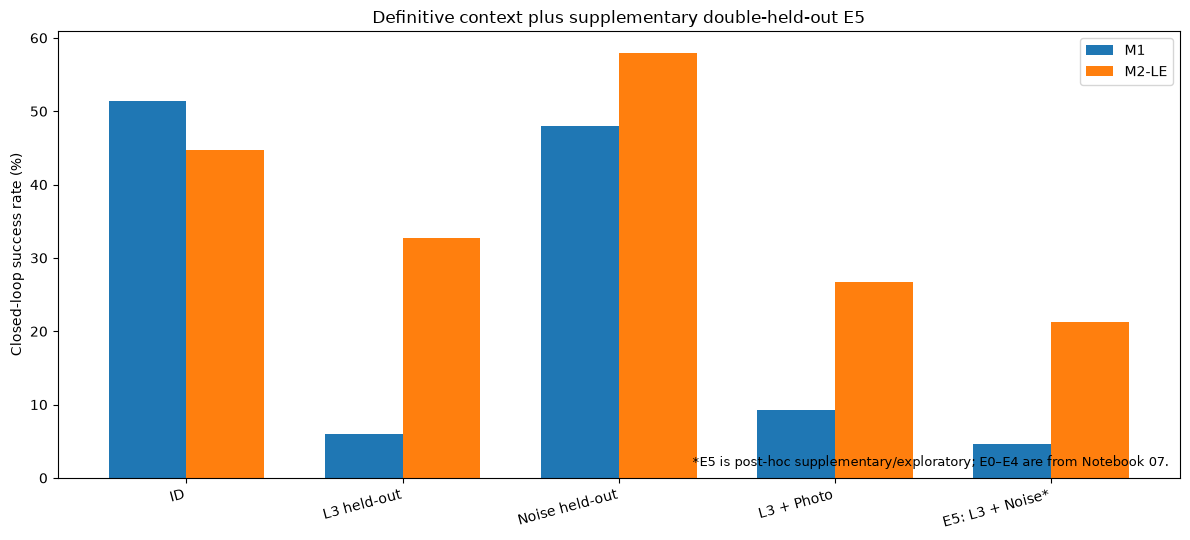

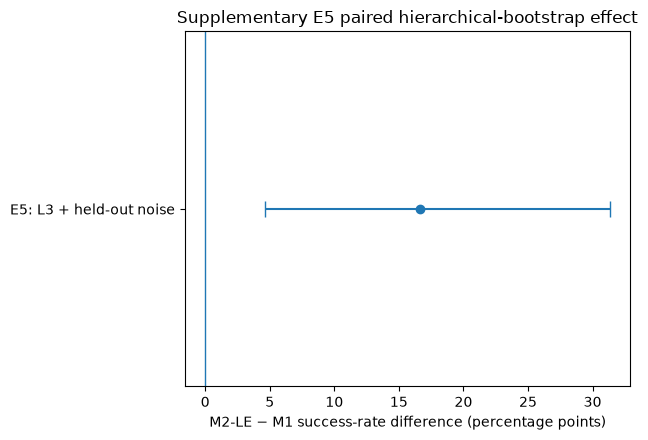

Supplementary context figure: /home/leeming/projects/deep-learning-vla-robustness/results/figures/supplementary_double_heldout/supplementary_e5_context.png
Supplementary effect figure: /home/leeming/projects/deep-learning-vla-robustness/results/figures/supplementary_double_heldout/supplementary_e5_paired_effect.png


In [18]:
plot_df = context_df.copy()
x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x - width/2, plot_df["m1_mean_success"] * 100.0, width, label="M1")
ax.bar(x + width/2, plot_df["m2le_mean_success"] * 100.0, width, label="M2-LE")
ax.set_ylabel("Closed-loop success rate (%)")
ax.set_title("Definitive context plus supplementary double-held-out E5")
ax.set_xticks(x)
ax.set_xticklabels([
    "ID", "L3 held-out", "Noise held-out", "L3 + Photo", "E5: L3 + Noise*"
], rotation=15, ha="right")
ax.legend()
ax.text(
    0.99, 0.02,
    "*E5 is post-hoc supplementary/exploratory; E0–E4 are from Notebook 07.",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9
)
fig.tight_layout()

CONTEXT_FIGURE_PATH = FIGURES_DIR / "supplementary_e5_context.png"
fig.savefig(CONTEXT_FIGURE_PATH, dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
delta = float(e5_effect_df.iloc[0]["observed_delta_pp"])
lo = float(e5_effect_df.iloc[0]["bootstrap_95_lower_pp"])
hi = float(e5_effect_df.iloc[0]["bootstrap_95_upper_pp"])
ax.errorbar([delta], [0], xerr=[[delta-lo], [hi-delta]], fmt="o", capsize=6)
ax.axvline(0, linewidth=1)
ax.set_yticks([0])
ax.set_yticklabels(["E5: L3 + held-out noise"])
ax.set_xlabel("M2-LE − M1 success-rate difference (percentage points)")
ax.set_title("Supplementary E5 paired hierarchical-bootstrap effect")
fig.tight_layout()
EFFECT_FIGURE_PATH = FIGURES_DIR / "supplementary_e5_paired_effect.png"
fig.savefig(EFFECT_FIGURE_PATH, dpi=180, bbox_inches="tight")
plt.show()

print("Supplementary context figure:", CONTEXT_FIGURE_PATH)
print("Supplementary effect figure:", EFFECT_FIGURE_PATH)


## 19. Report interpretation boundary

Use E5 in the report as a **supplementary exploratory stress test**, after the definitive E0–E4 results.

### Appropriate interpretation

- E5 asks whether the robustness pattern observed separately for held-out language and held-out sensor noise survives their simultaneous composition.
- It strengthens the **critical-analysis / limitations** discussion because both E5 components are outside the robustness-training categories.
- Its result can support or challenge the interpretation of robustness **without changing the original primary conclusion**.

### Do not claim

- that E5 was preregistered with E0–E4;
- that its raw p-value belongs to Notebook 07's original Holm-corrected family;
- that E5 covers all real-world distribution shifts;
- that E5 justifies any retraining or checkpoint replacement.

### Suggested report placement

Place E5 after the definitive results under a subsection such as **“Supplementary Double-Held-Out Stress Test.”** Explicitly state that it was motivated by the Notebook 07 finding that L3 showed strong multi-seed support while held-out sensor noise showed directional support.


## 20. Final reproducibility and exploratory status


In [19]:
final_checks = {
    "Notebook 07 prerequisite PASS": notebook07_summary["technical_status"] == "PASS",
    "Notebook 07 definitive 2050/2050": int(notebook07_summary["completed_episodes"]) == 2050,
    "Six primary frozen checkpoints": len(model_registry_df) == 6,
    "Training budget remains 25k": bool((model_registry_df["training_steps"].astype(int) == 25000).all()),
    "No training or model replacement": evaluation_protocol["training_or_tuning_in_notebook07b"] is False,
    "Protocol frozen": EVALUATION_PROTOCOL_PATH.exists(),
    "300 planned episodes": PLANNED_EPISODES == 300,
    "300 completed episodes": COMPLETED_EPISODES == 300,
    "Zero missing episodes": MISSING_EPISODES == 0,
    "All system statuses PASS": bool((episode_results_df["system_status"] == "PASS").all()),
    "Six per-seed summaries": len(condition_summary_df) == 6,
    "150 paired comparisons": len(paired_e5_df) == 150,
    "Hierarchical effect complete": len(e5_effect_df) == 1,
    "Notebook 07 context table complete": len(context_df) == 5,
    "Generalization-gap summary complete": len(e5_gap_summary_df) == 2,
    "Supplementary figures complete": CONTEXT_FIGURE_PATH.exists() and EFFECT_FIGURE_PATH.exists(),
}

final_checks = {k: bool(v) for k, v in final_checks.items()}
status_df = pd.DataFrame([
    {"check": k, "status": "PASS" if v else "FAIL"}
    for k, v in final_checks.items()
])
display(status_df)
NOTEBOOK_07B_PASS = all(final_checks.values())

summary_path = METRICS_DIR / "notebook07b_summary.json"
notebook07b_summary = {
    "notebook": "07b_supplementary_double_heldout_stress_test",
    "technical_status": "PASS" if NOTEBOOK_07B_PASS else "FAIL",
    "methodological_status": "SUPPLEMENTARY_EXPLORATORY",
    "condition_id": E5_CONDITION_ID,
    "condition": CONDITIONS[E5_CONDITION_ID],
    "evaluation_protocol_sha256": EVALUATION_PROTOCOL_SHA256,
    "project_git_sha": PROJECT_GIT_SHA,
    "frozen_training_steps": 25000,
    "checkpoint_count": 6,
    "planned_episodes": PLANNED_EPISODES,
    "completed_episodes": COMPLETED_EPISODES,
    "paired_episodes": len(paired_e5_df),
    "post_ood_training": False,
    "post_ood_model_replacement": False,
    "included_in_original_notebook07_holm_family": False,
    "effect_results": str((METRICS_DIR / "e5_hierarchical_paired_effect.csv").relative_to(REPO_ROOT)),
    "context_results": str((METRICS_DIR / "e5_context_with_notebook07.csv").relative_to(REPO_ROOT)),
    "technical_checks": final_checks,
}
with open(summary_path, "w") as f:
    json.dump(notebook07b_summary, f, indent=2)

print("=" * 88)
print("NOTEBOOK 07b — SUPPLEMENTARY DOUBLE-HELD-OUT STRESS TEST")
print("=" * 88)
for key, value in final_checks.items():
    print(f"{key:<70} {'PASS' if value else 'FAIL'}")
print("-" * 88)
print(f"{'NOTEBOOK 07b TECHNICAL STATUS':<70} {'PASS' if NOTEBOOK_07B_PASS else 'FAIL'}")
print(f"{'METHODOLOGICAL STATUS':<70} SUPPLEMENTARY / EXPLORATORY")
print(f"{'FROZEN CHECKPOINTS':<70} 6")
print(f"{'CLOSED-LOOP EPISODES':<70} {COMPLETED_EPISODES}/{PLANNED_EPISODES}")
print(f"{'POST-OOD TRAINING / MODEL REPLACEMENT':<70} NONE")
print("-" * 88)
print("Summary:", summary_path)

assert NOTEBOOK_07B_PASS, "Notebook 07b contains an incomplete supplementary artifact."


,check,status
0,Notebook 07 prerequisite PASS,PASS
1,Notebook 07 definitive 2050/2050,PASS
2,Six primary frozen checkpoints,PASS
3,Training budget remains 25k,PASS
4,No training or model replacement,PASS
5,Protocol frozen,PASS
6,300 planned episodes,PASS
7,300 completed episodes,PASS
8,Zero missing episodes,PASS
9,All system statuses PASS,PASS


NOTEBOOK 07b — SUPPLEMENTARY DOUBLE-HELD-OUT STRESS TEST
Notebook 07 prerequisite PASS                                          PASS
Notebook 07 definitive 2050/2050                                       PASS
Six primary frozen checkpoints                                         PASS
Training budget remains 25k                                            PASS
No training or model replacement                                       PASS
Protocol frozen                                                        PASS
300 planned episodes                                                   PASS
300 completed episodes                                                 PASS
Zero missing episodes                                                  PASS
All system statuses PASS                                               PASS
Six per-seed summaries                                                 PASS
150 paired comparisons                                                 PASS
Hierarchical effect complete   

## 21. Handoff to Notebook 08

After Notebook 07b passes, **all experimentation is closed**.

Notebook 08 should consume, not modify:

1. Notebook 05/05b training-budget evidence;
2. Notebook 06 frozen final model registry;
3. Notebook 07 definitive E0–E4 evidence;
4. Notebook 07b supplementary E5 evidence.

The report must keep the hierarchy explicit:

- **Primary/confirmatory evidence:** Notebook 07 (`E0–E4`)
- **Supplementary/exploratory evidence:** Notebook 07b (`E5`)

Any further ideas generated by E5 belong under **Future Work**, not a new training cycle.
